<a href="https://colab.research.google.com/github/mcarden4-netizen/Homework-Intro-to-ML/blob/Homework/Homework6Part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
drive.mount('/content/drive')

filetest = '/content/drive/My Drive/Cancer.csv'
data = pd.DataFrame(pd.read_csv(filetest))
data.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [7]:
Y = data['diagnosis'].map({'M': 1, 'B': 0}).to_numpy()

X = data.drop(columns=['id', 'diagnosis', 'Unnamed: 32'])

X = X.astype(np.float32)

In [8]:
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.20, random_state=50, stratify=Y)

In [9]:
scaler = StandardScaler()

Xtrain = scaler.fit_transform(Xtrain).astype(np.float32)
Xtest = scaler.transform(Xtest).astype(np.float32)

In [10]:
Xfit, Xval, Yfit, Yval = train_test_split(Xtrain, Ytrain, test_size=0.20, random_state=50, stratify=Ytrain)

torch.manual_seed(50)
np.random.seed(50)

Xfit = torch.tensor(Xfit, dtype=torch.float32)
Yfit = torch.tensor(Yfit, dtype=torch.float32).reshape(-1, 1)

Xval = torch.tensor(Xval, dtype=torch.float32)
Yval = torch.tensor(Yval, dtype=torch.float32).reshape(-1, 1)

Xtrain_tensor = torch.tensor(Xtrain, dtype=torch.float32)
Ytrain_tensor = torch.tensor(Ytrain, dtype=torch.float32).reshape(-1, 1)

Xtest_tensor = torch.tensor(Xtest, dtype=torch.float32)

In [11]:
class Cancer(nn.Module):
  def __init__(self, input_size):
    super().__init__()

    self.hidden_linear1 = nn.Linear(input_size, 64)
    self.hidden_act1 = nn.ReLU()

    self.hidden_linear2 = nn.Linear(64, 32)
    self.hidden_act2 = nn.ReLU()

    self.output_linear = nn.Linear(32, 1)

  def forward(self, input):
    hidden = self.hidden_linear1(input)
    active = self.hidden_act1(hidden)

    hidden = self.hidden_linear2(active)
    active = self.hidden_act2(hidden)

    output = self.output_linear(active)

    return output

In [12]:
model = Cancer(Xtrain.shape[1])

In [24]:
learning_rate = 0.001
epochs = 5000

means = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float('inf')

In [25]:
for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    train_logits = model(Xfit)
    loss = means(train_logits, Yfit)

    loss.backward()
    optimizer.step()

    train_loss = loss.item()

    model.eval()

    with torch.no_grad():

        train_probabilities = torch.sigmoid(model(Xfit))
        train_predictions = (train_probabilities >= 0.5).float()

        train_accuracy = (train_predictions == Yfit).float().mean().item()

        val_logits = model(Xval)
        val_loss = means(val_logits, Yval).item()

        val_probabilities = torch.sigmoid(val_logits)
        val_predictions = (val_probabilities >= 0.5).float()

        val_accuracy = (val_predictions == Yval).float().mean().item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch + 1}: " f"Training Loss = {train_loss:.4f}, " f"Validation Loss = {val_loss:.4f}, " f"Training Accuracy = {train_accuracy:.4f}, " f"Validation Accuracy = {val_accuracy:.4f}")

print("Best validation loss:", best_val_loss)

Epoch 500: Training Loss = 0.0008, Validation Loss = 0.0727, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 1000: Training Loss = 0.0002, Validation Loss = 0.0937, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 1500: Training Loss = 0.0001, Validation Loss = 0.1062, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 2000: Training Loss = 0.0000, Validation Loss = 0.1152, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 2500: Training Loss = 0.0000, Validation Loss = 0.1225, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 3000: Training Loss = 0.0000, Validation Loss = 0.1288, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 3500: Training Loss = 0.0000, Validation Loss = 0.1345, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 4000: Training Loss = 0.0000, Validation Loss = 0.1400, Training Accuracy = 1.0000, Validation Accuracy = 0.9560
Epoch 4500: Training Loss = 0.0000, Validation Lo

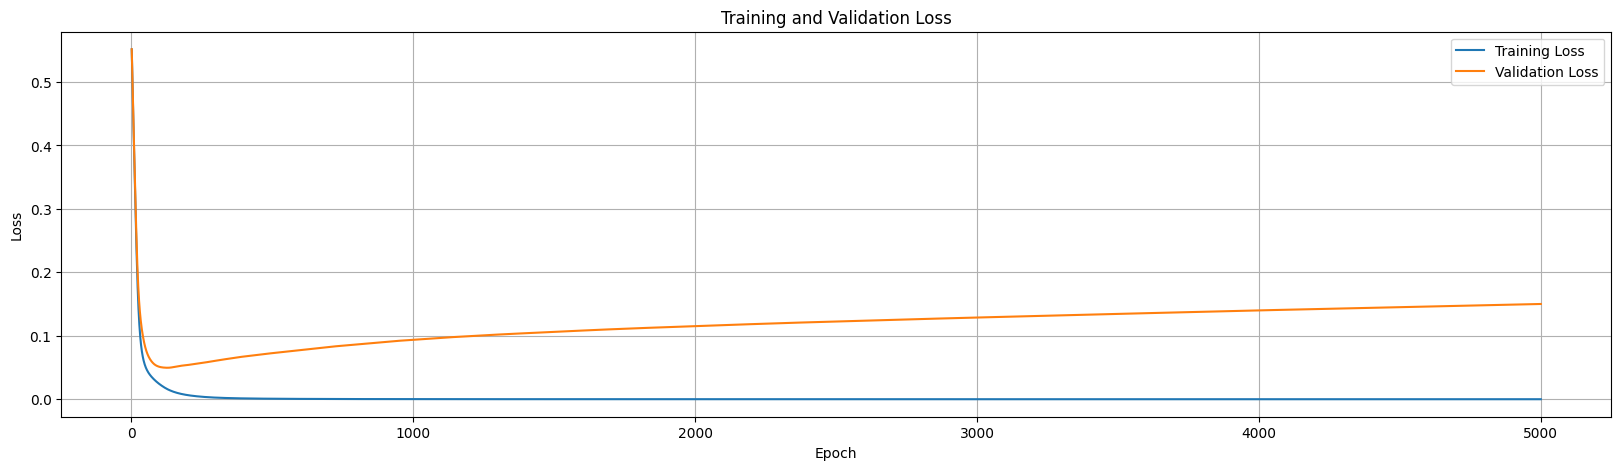

In [26]:
plt.figure(figsize=(20, 5))

plt.plot(range(1, epochs + 1), train_losses, label='Training Loss')

plt.plot(range(1, epochs + 1), val_losses,label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

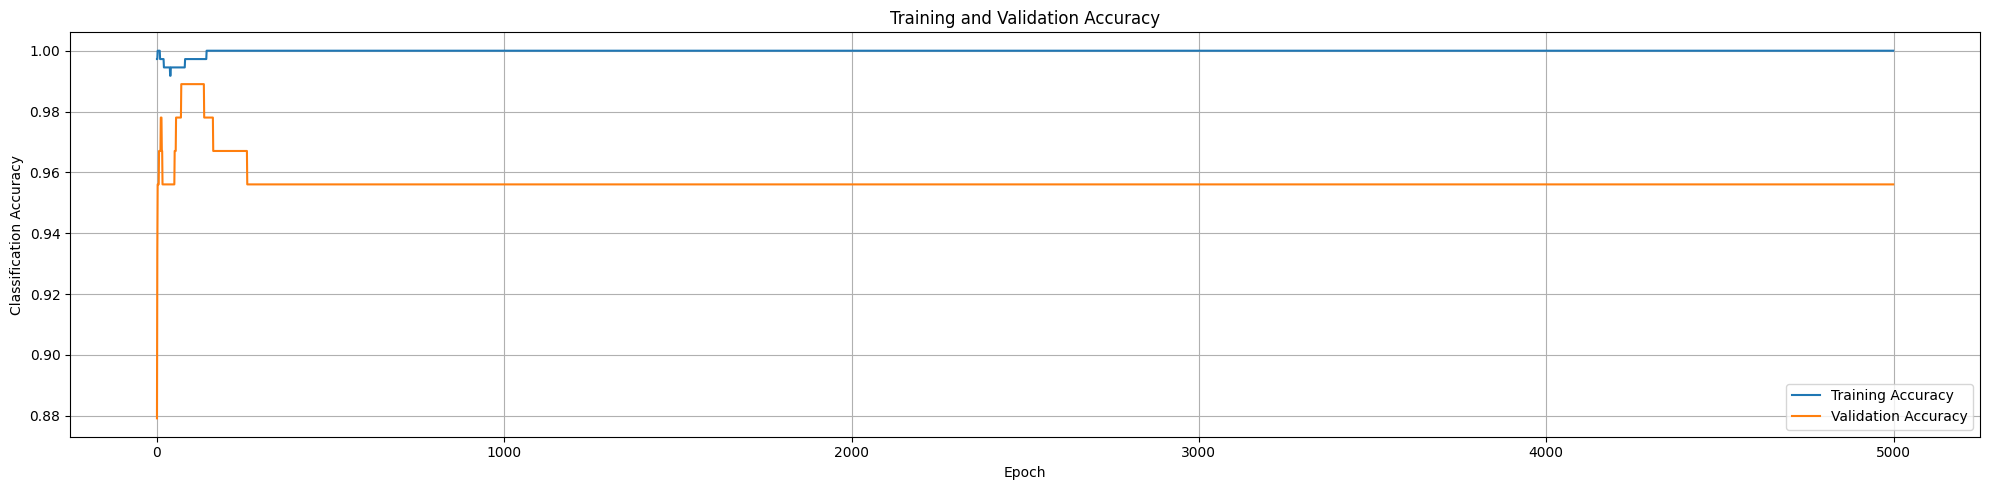

In [28]:
plt.figure(figsize=(20, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Classification Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
torch.manual_seed(50)

final_model = Cancer(Xtrain.shape[1])

final_optimizer = torch.optim.Adam(final_model.parameters(), lr=learning_rate)

for epoch in range(epoch):

    final_model.train()

    final_optimizer.zero_grad()

    predictions = final_model(Xtrain_tensor)
    loss = means(predictions, Ytrain_tensor)

    loss.backward()
    final_optimizer.step()

In [30]:
final_model.eval()

with torch.no_grad():
    test_logits = final_model(Xtest_tensor)
    test_probabilities = torch.sigmoid(test_logits)

    Ypred = (test_probabilities >= 0.5).int().numpy().flatten()

Yactual = Ytest

accuracy = accuracy_score(Yactual, Ypred)

precision = precision_score(Yactual, Ypred, pos_label=1, zero_division=0)

recall = recall_score(Yactual, Ypred, pos_label=1, zero_division=0)

f1 = f1_score(Yactual, Ypred, pos_label=1, zero_division=0)

print("\n========== Test Set Results ==========")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


========== Test Set Results ==========
Accuracy:  0.9474
Precision: 0.9286
Recall:    0.9286
F1 Score:  0.9286


In [32]:
Job = confusion_matrix(Yactual, Ypred,)

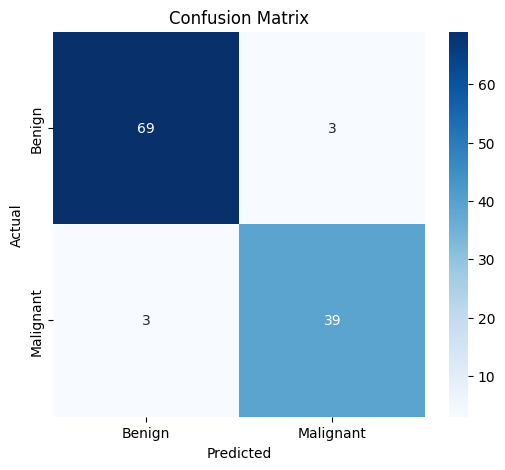

In [35]:
plt.figure(figsize=(6, 5))

sns.heatmap(Job, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()